# فاز دوم: پیش‌پردازش، مهندسی ویژگی و تحلیل مناطق

این نوت‌بوک ماژول‌های `src/` را اجرا می‌کند. بازه آموزش تا ۲۱ ژانویه و بازه اعتبارسنجی از ۲۲ ژانویه است؛ پروفایل خوشه‌بندی و تشخیص ناهنجاری فقط با داده‌های آموزش برازش می‌شوند. ویژگی‌های تاخیری صرفاً از ساعات گذشته استفاده می‌کنند و ۱۶۸ ساعت ابتدایی برای تکمیل سابقه هفتگی از خروجی مدل‌سازی حذف می‌شود.

فایل خام مورد انتظار: `data/yellow_tripdata_2024-01.parquet`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.anomaly_detection import fit_demand_profiles, flag_demand_anomalies
from src.clustering import fit_zone_clusters
from src.features import add_cluster_labels, add_temporal_features, prepare_modeling_frame
from src.preprocessing import RAW_COLUMNS, clean_and_aggregate

RAW_PATH = ROOT / 'data' / 'yellow_tripdata_2024-01.parquet'
OUTPUT_PATH = ROOT / 'data' / 'processed' / 'hourly_demand_features.parquet'
FIGURES = ROOT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
if not RAW_PATH.exists():
    raise FileNotFoundError(f'Raw data not found: {RAW_PATH}')
print(f'Raw data: {RAW_PATH}')

Raw data: D:\University\Project\DA.worktrees\read-code-artifact-md-and-implement\data\yellow_tripdata_2024-01.parquet


## پاک‌سازی، تجمیع و ویژگی‌های زمانی

سفرهای دارای مبلغ نامعتبر، مدت خارج از ۱ تا ۱۸۰ دقیقه، مسافت خارج از بازه معتبر یا ناحیه نامشخص حذف می‌شوند. شمار سفرها مستقل از `passenger_count` است؛ مقدار گمشده مسافر فقط برای ویژگی کمکی با ۱ جایگزین می‌شود. مجموعه نواحی از بازه آموزش ساخته می‌شود تا ناحیه‌های صرفاً دیده‌شده در اعتبارسنجی به فضای ویژگی نشت نکنند.

In [2]:
trips = pd.read_parquet(RAW_PATH, columns=list(RAW_COLUMNS))
hourly, attrition = clean_and_aggregate(trips)
del trips
zone_labels, cluster_metrics, zone_profiles = fit_zone_clusters(hourly)
features = add_cluster_labels(add_temporal_features(hourly), zone_labels)
anomaly_profiles = fit_demand_profiles(hourly)
anomaly_results = flag_demand_anomalies(hourly, anomaly_profiles)
features = features.merge(
    anomaly_results[['PULocationID', 'pickup_hour', 'anomaly_z_score', 'is_anomaly']],
    on=['PULocationID', 'pickup_hour'], how='left', validate='one_to_one'
)
features['is_anomaly'] = features['is_anomaly'].astype(bool)
features = prepare_modeling_frame(features)
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
features.to_parquet(OUTPUT_PATH, index=False)
print(f'Hourly panel: {len(hourly):,} rows; modeling frame: {len(features):,} rows')
print(f'Saved: {OUTPUT_PATH}')
display(zone_labels['cluster_name'].value_counts().rename_axis('cluster description').to_frame('zones'))

Hourly panel: 186,744 rows; modeling frame: 144,576 rows
Saved: D:\University\Project\DA.worktrees\read-code-artifact-md-and-implement\data\processed\hourly_demand_features.parquet


,zones
cluster description,
lower-demand evening-peak,214
higher-demand evening-peak,37


## جدول ریزش داده

این جدول تعداد حذف‌شده در هر مرحله را به‌صورت متوالی نشان می‌دهد. حذف‌ها فقط روی سفرهای خام انجام می‌شوند؛ ساعات بدون سفر در پنل کامل باقی می‌مانند و `trip_count=0` می‌گیرند.

,stage,removed,remaining
0,raw,0,2964624
1,pickup_date,18,2964606
2,positive_amounts,38340,2926266
3,valid_duration_1_to_180_min,31526,2894740
4,valid_distance_0_to_100_miles,35786,2858954
5,valid_pickup_zone,9969,2848985


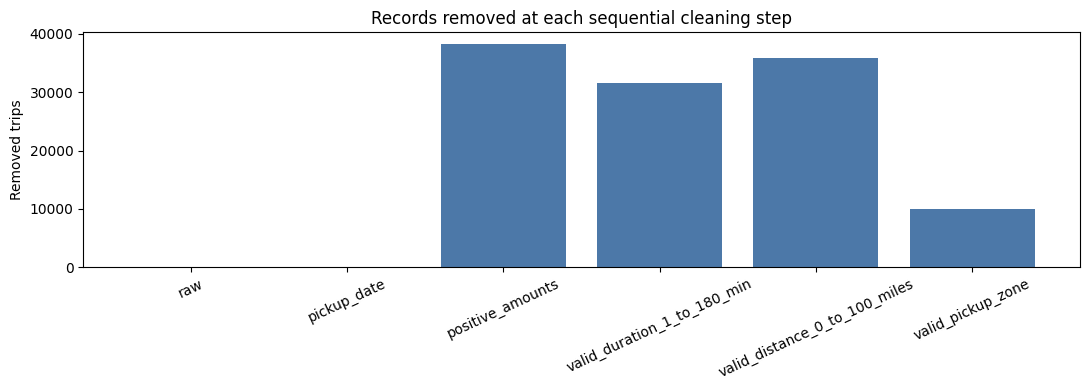

In [3]:
display(attrition)
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(attrition['stage'], attrition['removed'], color='#4c78a8')
ax.set(title='Records removed at each sequential cleaning step', ylabel='Removed trips')
ax.tick_params(axis='x', rotation=25)
fig.tight_layout()
fig.savefig(FIGURES / 'data_attrition_table.png', dpi=160)
plt.show()

## انتخاب تعداد خوشه‌ها و پروفایل تقاضا

استانداردسازی و K-Means فقط بر پروفایل‌های آموزش انجام می‌شود. نام خوشه‌ها توصیف داده‌محورِ شدت تقاضا و ساعت اوج هستند و نباید به‌عنوان نوع رسمی کاربری زمین تفسیر شوند.

,k,inertia,silhouette
0,3,1705.777531,0.785535
1,4,1280.942892,0.784855
2,5,1048.048325,0.785150


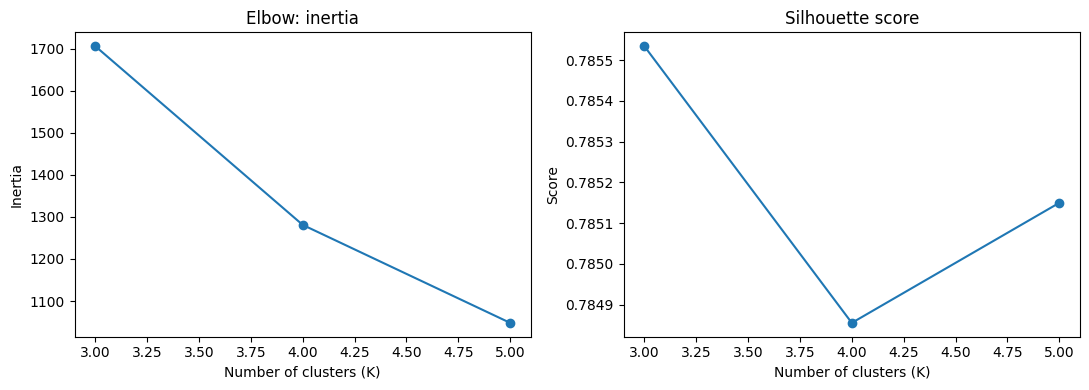

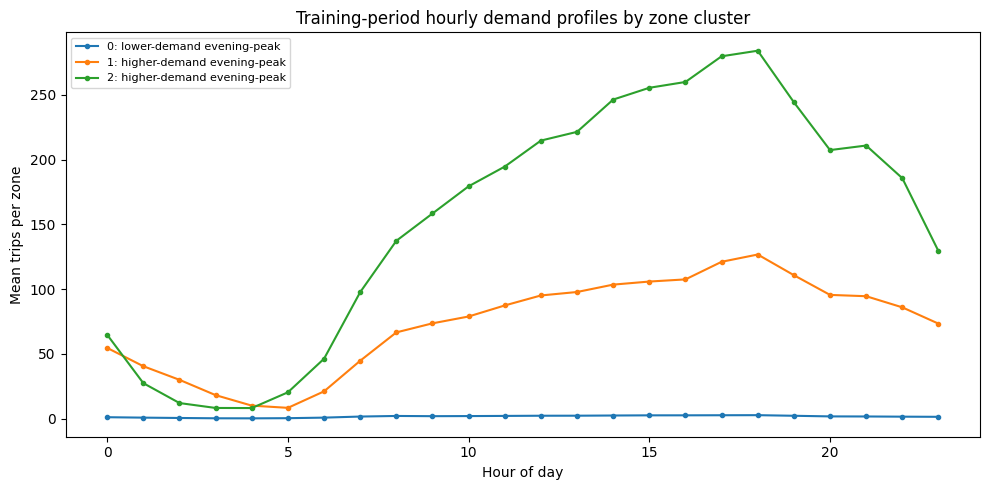

In [4]:
display(cluster_metrics)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(cluster_metrics['k'], cluster_metrics['inertia'], marker='o')
axes[0].set(title='Elbow: inertia', xlabel='Number of clusters (K)', ylabel='Inertia')
axes[1].plot(cluster_metrics['k'], cluster_metrics['silhouette'], marker='o')
axes[1].set(title='Silhouette score', xlabel='Number of clusters (K)', ylabel='Score')
fig.tight_layout()
fig.savefig(FIGURES / 'cluster_selection.png', dpi=160)
plt.show()

train_features = features.loc[features['pickup_hour'] < pd.Timestamp('2024-01-22')]
cluster_hourly = train_features.groupby(['zone_cluster', 'hour'])['trip_count'].mean().unstack(0)
fig, ax = plt.subplots(figsize=(10, 5))
for cluster in cluster_hourly.columns:
    name = zone_labels.loc[zone_labels['zone_cluster'].eq(cluster), 'cluster_name'].iloc[0]
    ax.plot(cluster_hourly.index, cluster_hourly[cluster], marker='.', label=f'{cluster}: {name}')
ax.set(title='Training-period hourly demand profiles by zone cluster', xlabel='Hour of day', ylabel='Mean trips per zone')
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / 'cluster_hourly_profiles.png', dpi=160)
plt.show()

## بررسی ناهنجاری‌ها

امتیاز Z نسبت به میانگین و انحراف معیار آموزش برای همان ناحیه، روز هفته و ساعت محاسبه شده است؛ در این split برای هر ترکیب فقط سه مشاهده آموزشی وجود دارد، پس این پرچم‌ها اکتشافی و حساس به نمونه‌های کم هستند. آن‌ها دلیل حذف داده نیستند. بدون داده مستقل آب‌وهوا/رویداد نمی‌توان یک جهش آماری را به رویداد واقعی مشخصی نسبت داد؛ ابتدا باید رکوردهای منبع و منابع بیرونی اعتبارسنجی شوند.

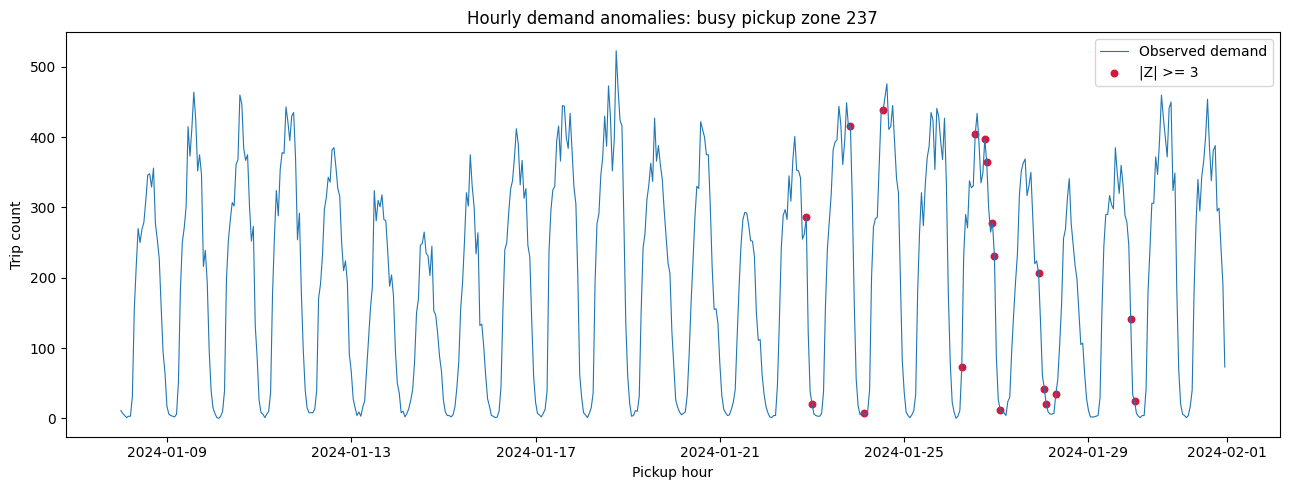

,pickup_hour,trip_count,anomaly_z_score,anomaly_direction
130128,2024-01-30 00:00:00,24,12.701706,above profile
129960,2024-01-23 00:00:00,21,7.505553,above profile
130055,2024-01-26 23:00:00,231,7.426499,above profile
130038,2024-01-26 06:00:00,73,6.928203,above profile
130058,2024-01-27 02:00:00,12,-6.350853,below profile
129987,2024-01-24 03:00:00,7,6.000000,above profile
130087,2024-01-28 07:00:00,35,5.444357,above profile
130045,2024-01-26 13:00:00,404,5.121176,above profile
130078,2024-01-27 22:00:00,207,4.666667,above profile
130050,2024-01-26 18:00:00,397,4.633522,above profile


,flagged hours (False = validation)
train_period,
False,1795


All flagged hours count trips that passed the documented cleaning checks. Statistical flags are not proof of data error or a named city event; weather/event attribution requires independent external records.


In [5]:
busy_zone = int(hourly.groupby('PULocationID')['trip_count'].sum().idxmax())
zone_anomalies = features.loc[features['PULocationID'].eq(busy_zone)].sort_values('pickup_hour')
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(zone_anomalies['pickup_hour'], zone_anomalies['trip_count'], linewidth=0.8, label='Observed demand')
anomalies = zone_anomalies.loc[zone_anomalies['is_anomaly']]
ax.scatter(anomalies['pickup_hour'], anomalies['trip_count'], color='crimson', s=22, label='|Z| >= 3')
ax.set(title=f'Hourly demand anomalies: busy pickup zone {busy_zone}', xlabel='Pickup hour', ylabel='Trip count')
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / 'demand_anomalies.png', dpi=160)
plt.show()
display(anomalies[['pickup_hour', 'trip_count', 'anomaly_z_score']].assign(
    anomaly_direction=np.where(anomalies['anomaly_z_score'] > 0, 'above profile', 'below profile')
).sort_values('anomaly_z_score', key=lambda values: values.abs(), ascending=False).head(20))
display(features.loc[features['is_anomaly']].groupby('train_period').size().rename('flagged hours (False = validation)').to_frame())
print('All flagged hours count trips that passed the documented cleaning checks. Statistical flags are not proof of data error or a named city event; weather/event attribution requires independent external records.')

## همبستگی ویژگی‌ها با هدف

همبستگی توصیفی و نه معیار اهمیت علّی است. برای آموزش مدل نهایی، تمام برازش‌ها باید فقط روی بازه آموزش انجام شوند.

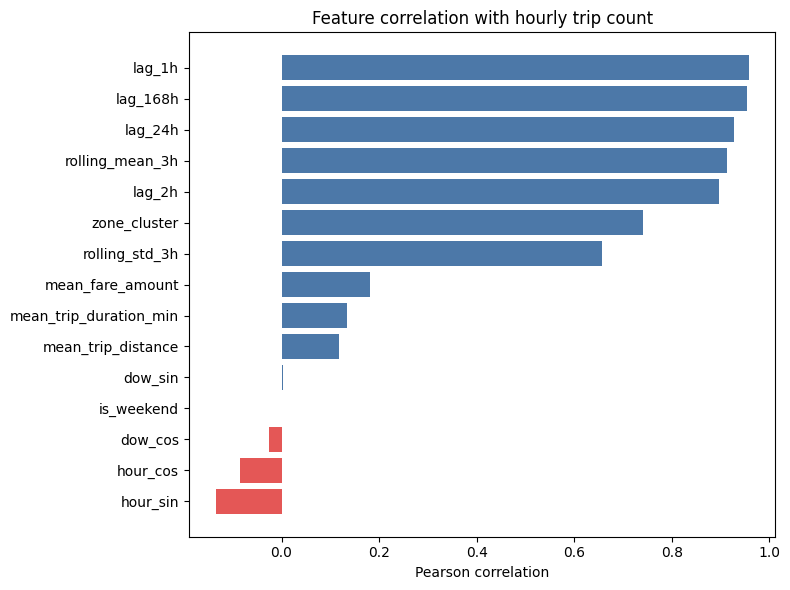

,correlation
hour_sin,-0.135314
hour_cos,-0.085910
dow_cos,-0.025713
is_weekend,0.001341
dow_sin,0.003382
mean_trip_distance,0.117065
mean_trip_duration_min,0.134851
mean_fare_amount,0.181570
rolling_std_3h,0.656696
zone_cluster,0.741402


Acceptance checks passed. Output rows: 144,576; null cells: 0


In [6]:
candidate_features = [
    'lag_1h', 'lag_2h', 'lag_24h', 'lag_168h', 'rolling_mean_3h',
    'rolling_std_3h', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos',
    'is_weekend', 'mean_fare_amount', 'mean_trip_distance',
    'mean_trip_duration_min', 'zone_cluster'
]
correlations = features[candidate_features + ['trip_count']].corr(numeric_only=True)['trip_count'].drop('trip_count').sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
colors = ['#e45756' if value < 0 else '#4c78a8' for value in correlations.values]
ax.barh(correlations.index, correlations.values, color=colors)
ax.set(title='Feature correlation with hourly trip count', xlabel='Pearson correlation')
fig.tight_layout()
fig.savefig(FIGURES / 'feature_correlations.png', dpi=160)
plt.show()
display(correlations.to_frame('correlation'))

assert not features[['lag_1h', 'lag_2h', 'lag_24h', 'lag_168h', 'rolling_mean_3h', 'rolling_std_3h']].isna().any().any()
assert features['pickup_hour'].min() >= pd.Timestamp('2024-01-08')
assert (features.loc[features['pickup_hour'] < pd.Timestamp('2024-01-22'), 'train_period']).all()
print(f'Acceptance checks passed. Output rows: {len(features):,}; null cells: {features.isna().sum().sum():,}')